# Thí nghiệm 1–2: toán tử GA và độ nhạy tham số

Viết lại theo chủ đề notebook tham chiếu; dùng package GA P1/P2 hiện tại.


**Cách chạy:** từ root cài `python -m pip install -r requirements.txt`, mở
`jupyter notebook`, chọn kernel/interpreter `.venv` vừa cài rồi **Restart Kernel & Run All**.
Trong VS Code, dùng **Select Kernel → Python Environments → .venv**. Nếu import lỗi,
kiểm tra kernel; không sửa sys.path. Notebook nhận diện root khi mở từ root hoặc `Experiment/`.

Quick mặc định dùng 5 seed cố định, run count và objective budget hữu hạn; Full là opt-in 25 seed.
Mỗi run có cooperative time cap và tổng solver time cap (không phải hard real-time).
Không ghi raw output ra file hay lặp đến khi đạt một nghiệm mong muốn. Chạy lại từ đầu để reset biến.
Chi phí là đơn vị của ma trận, không mặc định km. Cả 7 file có `known_optimum=None`;
không dùng hậu tố filename làm optimum/gap đã chứng minh.


In [1]:
from pathlib import Path
from dataclasses import replace
import json
import math
import platform
import statistics
from time import perf_counter
from IPython import get_ipython
from IPython.display import display, Markdown
import matplotlib.pyplot as plt

from ga_eho_tsp import __version__
from ga_eho_tsp.algorithms.ga import solve
from ga_eho_tsp.data.matrix_loader import load_matrix
from ga_eho_tsp.domain.models import GAConfig
from ga_eho_tsp.domain.objective import validate_route

get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'figure.dpi': 85, 'font.size': 9})
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'pyproject.toml').is_file() and (p / 'data').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Hãy mở Jupyter từ root dự án hoặc Experiment/.')

MODE = 'QUICK'  # Đổi thành FULL rồi Restart Kernel & Run All để dùng 25 seed.
assert MODE in {'QUICK', 'FULL'}
SEEDS = [11, 23, 37, 53, 71] if MODE == 'QUICK' else list(range(101, 126))
SOLVER_SECONDS_LIMIT = 120.0 if MODE == 'QUICK' else 600.0
MAX_RUNS = 150 if MODE == 'QUICK' else 1200
RUN_COUNT, SOLVER_SECONDS = 0, 0.0
SESSION_START = perf_counter()

def checked_solve(problem, config):
    global RUN_COUNT, SOLVER_SECONDS
    remaining = SOLVER_SECONDS_LIMIT - SOLVER_SECONDS
    if RUN_COUNT >= MAX_RUNS or remaining <= 0:
        raise RuntimeError('Vượt hạn mức notebook; không coi batch thiếu là đã hoàn thành.')
    config = replace(config, time_limit_seconds=min(5.0 if MODE == 'QUICK' else 15.0, remaining))
    result = solve(problem, config)
    RUN_COUNT += 1
    SOLVER_SECONDS += result.elapsed_seconds
    validate_route(result.best_route, problem.dimension)
    independent_cost = sum(problem.distance_matrix[result.best_route[i]][
        result.best_route[(i + 1) % problem.dimension]] for i in range(problem.dimension))
    assert math.isclose(result.best_distance, independent_cost, rel_tol=1e-12, abs_tol=1e-9)
    assert result.is_valid and result.evaluations <= config.max_evaluations
    assert result.history[0].iteration == 0
    assert result.history[-1].evaluations == result.evaluations
    assert all(b.best_so_far <= a.best_so_far for a, b in zip(result.history, result.history[1:]))
    assert result.metadata['local_search_full_evaluations'] <= result.evaluations
    return result

def show_table(headers, rows):
    text = '| ' + ' | '.join(headers) + ' |\n'
    text += '| ' + ' | '.join(['---'] * len(headers)) + ' |\n'
    text += '\n'.join('| ' + ' | '.join(map(str, row)) + ' |' for row in rows)
    display(Markdown(text))

print(f'Python {platform.python_version()} | ga_eho_tsp {__version__} | {MODE} | seeds={SEEDS}')


Python 3.11.9 | ga_eho_tsp 0.2.0 | QUICK | seeds=[11, 23, 37, 53, 71]


## Câu hỏi và giả thuyết
Selection, crossover và mutation nào phù hợp với bài 15 city dưới cùng budget?
Giả thuyết: ảnh hưởng phụ thuộc toán tử/budget, PMX không chắc hơn OX.
Thiết kế **one factor at a time**, không chạy tích 3×2×4. Sau đó khảo sát từng tham số.
Mọi cấu hình ở phần toán tử có cùng seeds, P40, elites2 và budget2000 trong Quick.
Các cap thế hệ ở phần sensitivity cố ý có thể dùng ít evaluations hơn và được báo riêng.


In [2]:
problem = load_matrix(ROOT/'data/15Cities-1194.txt')
BUDGET = 2000 if MODE == 'QUICK' else 6000
BASE = GAConfig(population_size=40, generations=2000, max_iterations=2000,
                max_evaluations=BUDGET, record_history_every=1)
operator_changes = {
    'control': {}, 'rank': {'selection_method': 'rank'},
    'roulette': {'selection_method': 'roulette_wheel'}, 'PMX': {'crossover_method': 'pmx'},
    'swap': {'mutation_method': 'swap'}, 'insertion': {'mutation_method': 'insertion'},
    'scramble': {'mutation_method': 'scramble'},
}
print(f'Dataset: {problem.name}, n={problem.dimension}, known_optimum={problem.known_optimum}')
print(f'Budget/run={BUDGET}, max_runs={MAX_RUNS}, tổng solver cap={SOLVER_SECONDS_LIMIT}s')


Dataset: 15Cities-1194, n=15, known_optimum=None
Budget/run=2000, max_runs=150, tổng solver cap=120.0s


## 1. Ablation toán tử
Control = tournament(3), OX(0.9), inversion(0.15), random, elites2.
Mỗi dòng chỉ đổi một yếu tố; mean/median/sample std dùng toàn bộ seed, không chọn run đẹp.


In [3]:
operator_runs = {}
for name, changes in operator_changes.items():
    operator_runs[name] = [checked_solve(problem, replace(BASE, seed=seed, **changes)) for seed in SEEDS]

def summarize_groups(groups):
    summary = {}
    for name, runs in groups.items():
        distances = [r.best_distance for r in runs]
        summary[name] = {
            'mean': statistics.mean(distances), 'median': statistics.median(distances),
            'std': statistics.stdev(distances), 'min': min(distances), 'max': max(distances),
            'evaluations_min': min(r.evaluations for r in runs),
            'evaluations_max': max(r.evaluations for r in runs),
            'runtime_mean': statistics.mean(r.elapsed_seconds for r in runs),
            'iterations_mean': statistics.mean(r.iterations_completed for r in runs),
        }
    return summary

def show_groups(summary):
    show_table(['Variant', 'Mean', 'Median', 'Sample std', 'Eval min–max', 'Runtime mean (s)'],
        [[name, f"{s['mean']:.2f}", f"{s['median']:.2f}", f"{s['std']:.2f}",
          f"{s['evaluations_min']}–{s['evaluations_max']}", f"{s['runtime_mean']:.4f}"]
         for name, s in summary.items()])

operator_summary = summarize_groups(operator_runs)
show_groups(operator_summary)


| Variant | Mean | Median | Sample std | Eval min–max | Runtime mean (s) |
| --- | --- | --- | --- | --- | --- |
| control | 1235.00 | 1225.00 | 43.86 | 2000–2000 | 0.0244 |
| rank | 1413.60 | 1402.00 | 81.79 | 2000–2000 | 0.0217 |
| roulette | 1400.80 | 1340.00 | 158.48 | 2000–2000 | 0.0218 |
| PMX | 1275.40 | 1279.00 | 38.34 | 2000–2000 | 0.0227 |
| swap | 1317.00 | 1289.00 | 113.40 | 2000–2000 | 0.0238 |
| insertion | 1319.80 | 1287.00 | 68.16 | 2000–2000 | 0.0236 |
| scramble | 1473.00 | 1391.00 | 152.78 | 2000–2000 | 0.0261 |

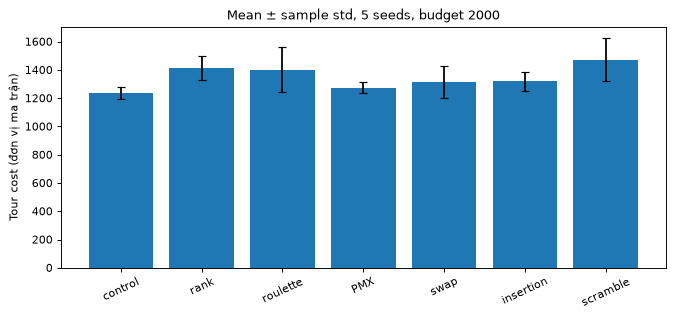

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.8))
names = list(operator_summary)
ax.bar(names, [operator_summary[n]['mean'] for n in names],
       yerr=[operator_summary[n]['std'] for n in names], capsize=3)
ax.set(title=f'Mean ± sample std, {len(SEEDS)} seeds, budget {BUDGET}',
       ylabel='Tour cost (đơn vị ma trận)')
ax.tick_params(axis='x', rotation=25)
fig.tight_layout(); plt.show(); plt.close(fig)


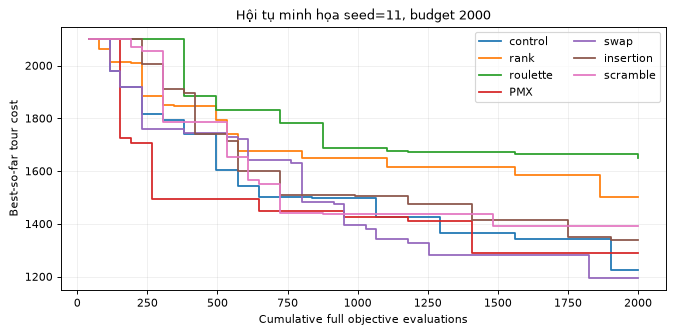

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
for name, runs in operator_runs.items():
    run = runs[0]  # Seed đầu đã cố định, không chọn seed tốt nhất.
    ax.step([s.evaluations for s in run.history], [s.best_so_far for s in run.history],
            where='post', label=name)
ax.set(title=f'Hội tụ minh họa seed={SEEDS[0]}, budget {BUDGET}',
       xlabel='Cumulative full objective evaluations', ylabel='Best-so-far tour cost')
ax.legend(ncol=2); ax.grid(alpha=.2)
fig.tight_layout(); plt.show(); plt.close(fig)


## 2. Độ nhạy tham số
Đổi riêng P20/P80, mutation0.05/0.30, elites0/4, crossover0.60, hoặc iteration cap.
Với hai cap, số vòng thực = min(generations,max_iterations).
Nếu muốn vượt250 thế hệ phải tăng **cả** hai field; ở đây base đã đặt2000.
`generations10` và `iteration_cap20` cố ý dừng sớm: không so chúng như cùng actual evaluations.


In [6]:
sensitivity_changes = {
    'P20': {'population_size': 20}, 'P80': {'population_size': 80},
    'mutation0.05': {'mutation_rate': .05}, 'mutation0.30': {'mutation_rate': .30},
    'generations10': {'generations': 10},
    'iteration_cap20': {'generations': 300, 'max_iterations': 20},
    'elite0': {'elite_count': 0}, 'elite4': {'elite_count': 4},
    'crossover0.60': {'crossover_rate': .60},
}
sensitivity_runs = {'control': operator_runs['control']}
for name, changes in sensitivity_changes.items():
    sensitivity_runs[name] = [checked_solve(problem, replace(BASE, seed=seed, **changes)) for seed in SEEDS]
sensitivity_summary = summarize_groups(sensitivity_runs)
show_groups(sensitivity_summary)
show_table(['Variant', 'generations', 'max_iterations', 'Mean committed iterations'],
    [[name, replace(BASE, **sensitivity_changes.get(name, {})).generations,
      replace(BASE, **sensitivity_changes.get(name, {})).max_iterations,
      f"{sensitivity_summary[name]['iterations_mean']:.1f}"] for name in sensitivity_runs])


| Variant | Mean | Median | Sample std | Eval min–max | Runtime mean (s) |
| --- | --- | --- | --- | --- | --- |
| control | 1235.00 | 1225.00 | 43.86 | 2000–2000 | 0.0244 |
| P20 | 1270.80 | 1241.00 | 71.71 | 2000–2000 | 0.0252 |
| P80 | 1296.40 | 1307.00 | 45.15 | 2000–2000 | 0.0245 |
| mutation0.05 | 1311.00 | 1302.00 | 107.35 | 2000–2000 | 0.0238 |
| mutation0.30 | 1320.00 | 1353.00 | 62.78 | 2000–2000 | 0.0258 |
| generations10 | 1670.00 | 1702.00 | 93.39 | 420–420 | 0.0063 |
| iteration_cap20 | 1476.00 | 1501.00 | 54.82 | 800–800 | 0.0104 |
| elite0 | 1276.40 | 1291.00 | 46.62 | 2000–2000 | 0.0261 |
| elite4 | 1224.60 | 1221.00 | 38.84 | 2000–2000 | 0.0250 |
| crossover0.60 | 1257.20 | 1242.00 | 53.45 | 2000–2000 | 0.0220 |

| Variant | generations | max_iterations | Mean committed iterations |
| --- | --- | --- | --- |
| control | 2000 | 2000 | 51.0 |
| P20 | 2000 | 2000 | 110.0 |
| P80 | 2000 | 2000 | 24.0 |
| mutation0.05 | 2000 | 2000 | 51.0 |
| mutation0.30 | 2000 | 2000 | 51.0 |
| generations10 | 10 | 2000 | 10.0 |
| iteration_cap20 | 300 | 20 | 20.0 |
| elite0 | 2000 | 2000 | 49.0 |
| elite4 | 2000 | 2000 | 54.0 |
| crossover0.60 | 2000 | 2000 | 51.0 |

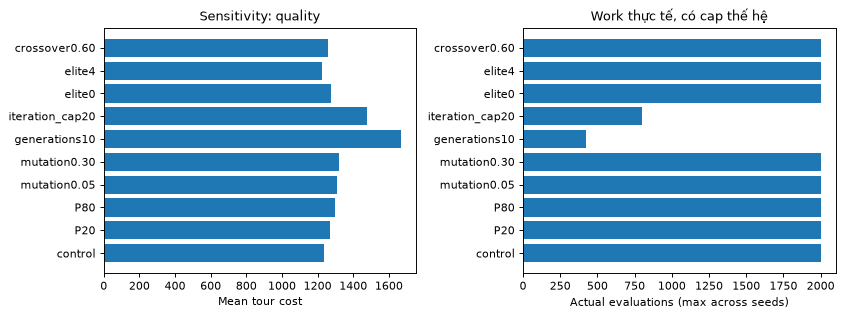

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
names = list(sensitivity_summary)
axes[0].barh(names, [sensitivity_summary[n]['mean'] for n in names])
axes[0].set(xlabel='Mean tour cost', title='Sensitivity: quality')
axes[1].barh(names, [sensitivity_summary[n]['evaluations_max'] for n in names])
axes[1].set(xlabel='Actual evaluations (max across seeds)', title='Work thực tế, có cap thế hệ')
fig.tight_layout(); plt.show(); plt.close(fig)


## 3. Diversity và giới hạn diễn giải
Diversity = (unique symmetric tours−1)/(P−1); tour đảo chiều tương đương được gộp.
Best-so-far không tăng; best-current/mean-fitness có thể dao động.
Đồ thị dưới là seed cố định, không phải đường mean nội suy giữa các seed.


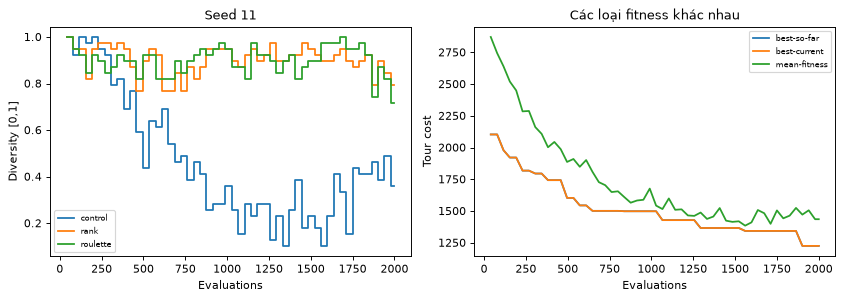

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for name in ['control', 'rank', 'roulette']:
    history = operator_runs[name][0].history
    axes[0].step([s.evaluations for s in history], [s.population_diversity for s in history],
                 where='post', label=name)
history = operator_runs['control'][0].history
for field, label in [('best_so_far', 'best-so-far'), ('best_current', 'best-current'), ('mean_fitness', 'mean-fitness')]:
    axes[1].plot([s.evaluations for s in history], [getattr(s, field) for s in history], label=label)
axes[0].set(xlabel='Evaluations', ylabel='Diversity [0,1]', title=f'Seed {SEEDS[0]}')
axes[1].set(xlabel='Evaluations', ylabel='Tour cost', title='Các loại fitness khác nhau')
for ax in axes: ax.legend(fontsize=7)
fig.tight_layout(); plt.show(); plt.close(fig)


## 4. Phần nâng cao (Full Mode opt-in)
Random vs NN/mixed/adaptive là biến thể riêng; không lẫn vào control random-only.
Quick Mode không chạy phần này; thí nghiệm4 khảo sát kỹ hơn ở các bài lớn.


In [9]:
advanced_summary = {}
if MODE == 'FULL':
    advanced_runs = {}
    for name, changes in {'mixed': {'initialization_method': 'mixed'},
                          'NN': {'initialization_method': 'nearest_neighbor'},
                          'adaptive': {'adaptive_mutation': True}}.items():
        advanced_runs[name] = [checked_solve(problem, replace(BASE, seed=seed, **changes)) for seed in SEEDS]
    advanced_summary = summarize_groups(advanced_runs)
    show_groups(advanced_summary)
else:
    display(Markdown('**Quick:** phần nâng cao này chưa chạy, không được báo như kết quả đã đo.'))


**Quick:** phần nâng cao này chưa chạy, không được báo như kết quả đã đo.

## Kết luận từ lần chạy này
Kết luận dưới được tạo từ dữ liệu thực trong kernel; không sử dụng optimum từ filename.


In [10]:
winner = min(operator_summary, key=lambda name: operator_summary[name]['mean'])
control_mean = operator_summary['control']['mean']
display(Markdown(f"Trong {len(SEEDS)} seed của bài {problem.dimension} city, **{winner}** có mean nhỏ nhất "
    f"({operator_summary[winner]['mean']:.2f}), control={control_mean:.2f}. "
    'Đây là quan sát trên mẫu nhỏ, không phải bằng chứng tối ưu hoặc ưu thế tổng quát. '
    'Các run bị iteration/time cap có work khác nhau đã hiển thị trong bảng. '
    'NN và local search cần ablation riêng trước khi so với EHO.'))
NOTEBOOK_REPORT = {'notebook': 'Experiment 1-2', 'mode': MODE, 'seeds': SEEDS, 'runs': RUN_COUNT,
    'budget': BUDGET, 'solver_seconds': SOLVER_SECONDS, 'operators': operator_summary,
    'sensitivity': sensitivity_summary, 'advanced': advanced_summary,
    'wall_seconds': perf_counter()-SESSION_START}
print(f'Hoàn thành {RUN_COUNT} run; solver time={SOLVER_SECONDS:.3f}s; không xuất raw files.')


Trong 5 seed của bài 15 city, **control** có mean nhỏ nhất (1235.00), control=1235.00. Đây là quan sát trên mẫu nhỏ, không phải bằng chứng tối ưu hoặc ưu thế tổng quát. Các run bị iteration/time cap có work khác nhau đã hiển thị trong bảng. NN và local search cần ablation riêng trước khi so với EHO.

Hoàn thành 80 run; solver time=1.766s; không xuất raw files.
